# **TP N°3 : Les Réseaux de Neurones Convolutifs**

**Elaboré par :** Ayeb Farah

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.models import model_from_json
from tensorflow.keras import backend as K

**Configurer le format des données (channels_first)**

In [10]:
K.set_image_data_format('channels_last')
seed = 7          # Fixer la graine aléatoire pour la reproductibilité des résultats
np.random.seed(seed)
tf.random.set_seed(seed)

**Définissez une fonction get_data_mnist() qui sera appelée par notre 1er
CNN, et qui retournera les différentes variables.**

In [11]:
def get_data_mnist():
    """
    Charge, reshape, normalise et encode les données MNIST.
    Retourne : (X_train, y_train), (X_test, y_test), num_classes
    """

    # Chargement : 60 000 images train + 10 000 images test
    # Chaque image = matrice 28x28, niveaux de gris (0 à 255)
    (X_train, y_train), (X_test, y_test) = mnist.load_data()

    # Format : (nb_samples, nb_channels, hauteur, largeur)
    X_train = X_train.reshape(X_train.shape[0], 28, 28, 1).astype('float32')
    X_test  = X_test.reshape(X_test.shape[0],  28, 28, 1).astype('float32')

    # Normalisation : pixels de [0-255] vers [0-1]
    X_train = X_train / 255.0
    X_test  = X_test  / 255.0

    # One-Hot Encoding des labels
    y_train = to_categorical(y_train)
    y_test  = to_categorical(y_test)

    num_classes = y_test.shape[1]

    print(f"X_train : {X_train.shape}")
    print(f"X_test  : {X_test.shape}")

    return (X_train, y_train), (X_test, y_test), num_classes



# Appel de la fonction
(X_train, y_train), (X_test, y_test), num_classes = get_data_mnist()

X_train : (60000, 28, 28, 1)
X_test  : (10000, 28, 28, 1)


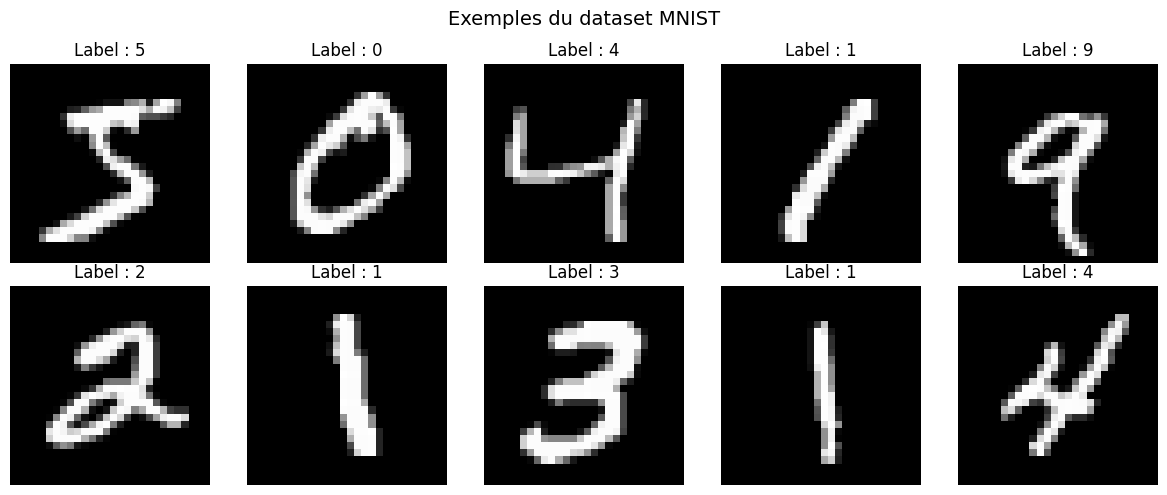

In [12]:
import matplotlib.pyplot as plt

# Afficher quelques exemples du dataset
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
(X_raw, y_raw), _ = mnist.load_data()  # version non-reshapée pour affichage

for i, ax in enumerate(axes.flat):
    ax.imshow(X_raw[i], cmap='gray')
    ax.set_title(f"Label : {y_raw[i]}")
    ax.axis('off')

plt.suptitle("Exemples du dataset MNIST", fontsize=14)
plt.tight_layout()
plt.show()

**Évalue un modèle et affiche son score et taux d'erreur.**

In [13]:
def print_model_error_rate(model, X_test, y_test, model_name="Modèle"):
    scores = model.evaluate(X_test, y_test, verbose=0)
    print(f"\n{'='*40}")
    print(f"  {model_name}")
    print(f"  Score      : {scores[1]*100:.2f}%")
    print(f"  Taux erreur: {(100 - scores[1]*100):.2f}%")
    print(f"{'='*40}")

**Construction du premier modèle (Small CNN)**

 Pour construire le premier modèle CNN (Small CNN)
    
    Architecture suivante est utilisée :
    - Conv2D: 64 filtres 3x3 + ReLU
    - Conv2D: 32 filtres 3x3 + ReLU
    - Flatten
    - Dense: 10 neurones + Softmax

In [15]:
def small_model(num_classes):
    model = Sequential()

    # Première couche de convolution 64 filtres 3x3 + ReLU
    model.add(Conv2D(64, (3, 3), input_shape=(28, 28, 1), activation='relu'))

    # Deuxième couche de convolution 32 filtres 3x3 + ReLU
    model.add(Conv2D(32, (3, 3), activation='relu'))

    # Aplatir les caractéristiques : Flatten → vecteur 1D
    model.add(Flatten())

    # Couche de sortie
    model.add(Dense(num_classes, activation='softmax'))

    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    model.summary()
    return model


# Entraînement Small CNN
print("\n Entraînement Small CNN")
m_small = small_model(num_classes)

history_small = m_small.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=200,
    verbose=1
)

print_model_error_rate(m_small, X_test, y_test, "Small CNN")


 Entraînement Small CNN


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 24, 24, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │       184,330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,434 (794.66 KB)

 Trainable params: 203,434 (794.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 144s 472ms/step - accuracy: 0.9334 - loss: 0.2325 - val_accuracy: 0.9743 - val_loss: 0.0797
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 148s 491ms/step - accuracy: 0.9795 - loss: 0.0685 - val_accuracy: 0.9806 - val_loss: 0.0605
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 145s 484ms/step - accuracy: 0.9852 - loss: 0.0488 - val_accuracy: 0.9818 - val_loss: 0.0573
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 144s 481ms/step - accuracy: 0.9895 - loss: 0.0362 - val_accuracy: 0.9840 - val_loss: 0.0563
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 139s 464ms/step - accuracy: 0.9923 - loss: 0.0275 - val_accuracy: 0.9842 - val_loss: 0.0572
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 142s 465ms/step - accuracy: 0.9937 - loss: 0.0218 - val_accuracy: 0.9838 - val_loss: 0.0607
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 147s 491ms/step - accuracy: 0.9947 - loss: 0.0173 - val_accuracy: 0.9847 - val_loss: 0.0593
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 197s 474ms/step - accuracy: 0.9954 -

 **Construction du modèle Medium**

In [16]:
def medium_model(num_classes):
    model = Sequential()
    model.add(Conv2D(32, (5, 5), input_shape=(28, 28, 1), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.2))
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    model.summary()
    return model


m_medium = medium_model(num_classes)

history_medium = m_medium.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=200,
    verbose=1
)

print_model_error_rate(m_medium, X_test, y_test, "Medium CNN")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 592,074 (2.26 MB)

 Trainable params: 592,074 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 106ms/step - accuracy: 0.9306 - loss: 0.2441 - val_accuracy: 0.9747 - val_loss: 0.0827
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 108ms/step - accuracy: 0.9766 - loss: 0.0786 - val_accuracy: 0.9816 - val_loss: 0.0596
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 109ms/step - accuracy: 0.9832 - loss: 0.0559 - val_accuracy: 0.9842 - val_loss: 0.0489
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 33s 111ms/step - accuracy: 0.9865 - loss: 0.0434 - val_accuracy: 0.9867 - val_loss: 0.0412
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 31s 104ms/step - accuracy: 0.9893 - loss: 0.0345 - val_accuracy: 0.9872 - val_loss: 0.0381
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 103ms/step - accuracy: 0.9908 - loss: 0.0288 - val_accuracy: 0.9859 - val_loss: 0.0397
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - accuracy: 0.9928 - loss: 0.0236 - val_accuracy: 0.9885 - val_loss: 0.0358
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 32s 108ms/step - accuracy: 0.9940 - loss: 0

 **Construction du modèle Large**

In [17]:
def large_model(num_classes):
    model = Sequential()
    model.add(Conv2D(30, (5, 5), input_shape=(28, 28, 1), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Conv2D(15, (3, 3), activation='relu'))
    model.add(Dropout(0.2))
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    model.summary()
    return model

m_large = large_model(num_classes)
history_large = m_large.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=200,
    verbose=1
)

print_model_error_rate(m_large, X_test, y_test, "Large CNN")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 30)     │           780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 10, 10, 15)     │         4,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 10, 15)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       192,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         6,450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,933 (796.61 KB)

 Trainable params: 203,933 (796.61 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 121ms/step - accuracy: 0.9128 - loss: 0.2844 - val_accuracy: 0.9793 - val_loss: 0.0678
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 117ms/step - accuracy: 0.9765 - loss: 0.0771 - val_accuracy: 0.9826 - val_loss: 0.0534
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 114ms/step - accuracy: 0.9824 - loss: 0.0558 - val_accuracy: 0.9839 - val_loss: 0.0486
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 43s 121ms/step - accuracy: 0.9868 - loss: 0.0432 - val_accuracy: 0.9864 - val_loss: 0.0423
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 123ms/step - accuracy: 0.9891 - loss: 0.0346 - val_accuracy: 0.9889 - val_loss: 0.0371
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - accuracy: 0.9905 - loss: 0.0301 - val_accuracy: 0.9887 - val_loss: 0.0344
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 35s 118ms/step - accuracy: 0.9918 - loss: 0.0253 - val_accuracy: 0.9889 - val_loss: 0.0328
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 35s 116ms/step - accuracy: 0.9925 - loss: 0

**Fonctions de sauvegarde et chargement**

In [21]:
def save_keras_model(model, filename):
    model_json = model.to_json()
    with open(filename + ".json", "w") as f:
        f.write(model_json)
    model.save_weights(filename + ".weights.h5")
    print(f"Sauvegardé : {filename}.json + {filename}.h5")


In [22]:
def load_keras_model(filename):
    with open(filename + ".json", 'r') as f:
        loaded_model = model_from_json(f.read())
    loaded_model.load_weights(filename + ".weights.h5")
    loaded_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    print(f" Chargé : {filename}")
    return loaded_model

In [23]:
save_keras_model(m_small,  "small_cnn")
save_keras_model(m_medium, "medium_cnn")
save_keras_model(m_large,  "large_cnn")

Sauvegardé : small_cnn.json + small_cnn.h5
Sauvegardé : medium_cnn.json + medium_cnn.h5
Sauvegardé : large_cnn.json + large_cnn.h5
